# Лабораторная работа: полная конверсия ResNet-18 в SNN с частотным кодированием

## Цель работы

Самостоятельно реализовать конверсию предобученной `ResNet18` в спайковую сеть.

### План конверсии
1. Подготовка сети и калибровочного датасета.
2. Сбор статистик активаций на калибровочном датасете. Выбор активации отсечения.
3. Подготовка архитектуры. Слои BatchNorm сливаются с предшествующими свёртками
4. Замена нейронов. Слой ReLU заменяется на слой IF-нейронов с `reset-by-subtraction`;
5. Преобразование residual-блоков
6. Преобразование MaxPool

Этапы 1-4 реализованы в ноутбуках к лекции. Этапы 5-6 будут разобраны на лекции 6, но оставлены для самостоятельной реализации.

### Исследование
Исследовать качество полученной сети оценить для разных комбинаций параметров:
1. Длины временного окна $T=16,32,64,128,256$
2. Правила выбора активации отсечения: $max$, $p99$, $p99.9$

Для каждой комбинации оценить:
1. Качество классификацию ANN и SNN на тестовом фрагменте ImageNet. Не использовать для этого калибровочный датасет
2. Оценить переносимость признаков на любую выбранную задачу компьютерного зрения. Пример: сегментация, локализация.
3. Оценить число операций на одно изображение:
* MAC для ANN/SNN
* AC для ANN/SNN
* среднее число спайков на изображение
* среднее число спайков на один нейрон сети
* среднее число спайков на каждом слое сети

Ноутбук рассчитан на Google Colab с GPU. В режиме `FAST_MODE=True` используются небольшие подвыборки.

### Источники
* Презентации к лекциям 4,5
* Ноутбук с сетью VGG
* Статья по конверсии базовых свёрточных сетей
Rueckauer, B., Lungu, I. A., Hu, Y., Pfeiffer, M., & Liu, S. C. (2017). Conversion of continuous-valued deep networks to efficient event-driven networks for image classification. Frontiers in neuroscience, 11, 682.

* Статья по конверсии residual слоёв
Hu, Y., Tang, H., & Pan, G. (2021). Spiking deep residual networks. IEEE Transactions on Neural Networks and Learning Systems, 34(8), 5200-5205. URL:
https://arxiv.org/pdf/1805.01352


Можно использовать фреймворк SpikingJelly:
https://spikingjelly.readthedocs.io

## Теоретическая схема

Для ReLU-активации ANN $a_i^{(l)}\geq 0$ rate-конверсия использует число спайков IF-нейрона:

$$
\hat a_i^{(l)}(T)=\theta_l\frac{N_i^{(l)}(T)}{T},
$$

где $\theta_l$ — порог слоя, а $N_i^{(l)}(T)=\sum_{t=1}^{T}s_i^{(l)}[t]$.

Динамика IF-нейрона с мягким сбросом:

$$
u_i[t]=u_i[t-1]+I_i[t],
$$

$$
s_i[t]=H(u_i[t]-\theta_i),
$$

$$
u_i[t]\leftarrow u_i[t]-s_i[t]\theta_i.
$$

В отличие от `reset-to-zero`, вычитание порога сохраняет остаточный потенциал и уменьшает ошибку квантования частоты.

Выход IF-узла в программной модели записывается как $\theta s[t]$. На специализированном железе множитель $\theta$ можно заранее свернуть в веса следующего слоя, поэтому активный бинарный спайк инициирует прибавление предварительно масштабированного веса.

## 1. Установка и импорты

In [1]:
# В Colab основные пакеты уже установлены.
#!pip -q install gdown pandas tqdm spikingjelly==0.0.0.0.14

In [2]:
import copy
import json
import math
import random
import time
import zipfile
from collections import defaultdict, deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights
from torchvision.models.resnet import BasicBlock
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm
from spikingjelly.activation_based import base, functional, neuron

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


## 2. Конфигурация эксперимента

In [3]:
FAST_MODE = True
T_CHECKPOINTS = [16, 32, 64, 128, 256, 512, 1024]

# Число объектов для калибровки порогов и оценки классификации.
CALIBRATION_SAMPLES = 128 if FAST_MODE else 1024
CLASSIFICATION_SAMPLES = 128 if FAST_MODE else None
CLASSIFICATION_BATCH_SIZE = 8 if torch.cuda.is_available() else 2

# Высокий перцентиль устойчивее абсолютного максимума.
THRESHOLD_PERCENTILE = 0.999
ACTIVATION_SAMPLE_LIMIT = 100_000
POOL_WINDOW = max(T_CHECKPOINTS)
SEG_SIZE = 128
SEG_TRAIN_SAMPLES = 64 if FAST_MODE else 136
SEG_TEST_SAMPLES = 16 if FAST_MODE else 34
SEG_EPOCHS = 50 if FAST_MODE else 100

DATA_DIR = Path('/content/data') if Path('/content').exists() else Path('./data')
RESULTS_DIR = Path('/content/results') if Path('/content').exists() else Path('./results')
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print('T checkpoints:', T_CHECKPOINTS)
print('FAST_MODE:', FAST_MODE)

T checkpoints: [16, 32, 64, 128, 256, 512, 1024]
FAST_MODE: True


## 3. Фрагмент ImageNet: Imagenette

Ноутбук поддерживает фрагмент ImageNet в формате `ImageFolder`. По умолчанию используется ранее подготовленный ZIP-файл Imagenette на Google Drive.

Ожидаемая структура после распаковки:

```text
imagenette_subset/
  train/ или val/
    n01440764/
    n02102040/
    ...
```

Если файл уже находится на Google Drive, повторная загрузка не выполняется.

In [4]:
DOWNLOAD_URL = 'https://drive.google.com/file/d/1JdnAT2kfg5CHby3DeL9q0fHkVdpluSrL/view?usp=sharing'
DRIVE_ZIP = Path('/content/drive/MyDrive/imagenette_subset/imagenette_subset.zip')
LOCAL_ZIP = DATA_DIR / 'imagenette_subset.zip'
EXTRACT_DIR = DATA_DIR / 'imagenette_subset'

def prepare_imagenette_zip(download=True):
    """Монтирует Drive, при необходимости загружает ZIP и распаковывает его."""
    if Path('/content').exists():
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=False)
        except Exception as exc:
            print('Drive не смонтирован:', exc)

    zip_path = DRIVE_ZIP if DRIVE_ZIP.exists() else LOCAL_ZIP
    if not zip_path.exists() and download:
        import gdown
        LOCAL_ZIP.parent.mkdir(parents=True, exist_ok=True)
        gdown.download(url=DOWNLOAD_URL, output=str(LOCAL_ZIP), fuzzy=True, quiet=False)
        zip_path = LOCAL_ZIP

    if not zip_path.exists():
        raise FileNotFoundError(
            'ZIP не найден. Поместите его в DRIVE_ZIP или измените DOWNLOAD_URL.'
        )

    marker = EXTRACT_DIR / '.extracted'
    if not marker.exists():
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(EXTRACT_DIR)
        marker.touch()
    return EXTRACT_DIR

def find_imagefolder_root(root):
    """Ищет каталог val/train, содержащий папки классов ImageNet."""
    root = Path(root)
    candidates = []
    for path in [root, *root.rglob('*')]:
        if not path.is_dir():
            continue
        dirs = [p.name for p in path.iterdir() if p.is_dir()]
        if any(name.startswith('n') and len(name) == 9 for name in dirs):
            score = 2 if path.name == 'val' else 1 if path.name == 'train' else 0
            candidates.append((score, path))
    if not candidates:
        raise RuntimeError(f'Не найден ImageFolder внутри {root}')
    return sorted(candidates, key=lambda item: item[0], reverse=True)[0][1]

imagenette_root = find_imagefolder_root(prepare_imagenette_zip())
print('ImageFolder root:', imagenette_root)

ImageFolder root: data/imagenette_subset/imagenette_10k_subset


In [5]:
weights = ResNet18_Weights.DEFAULT
imagenet_transform = weights.transforms()

# Соответствие десяти WNID Imagenette исходным индексам ImageNet-1k.
IMAGENETTE_TO_IMAGENET = {
    'n01440764': 0,
    'n02102040': 217,
    'n02979186': 482,
    'n03000684': 491,
    'n03028079': 497,
    'n03394916': 566,
    'n03417042': 569,
    'n03425413': 571,
    'n03445777': 574,
    'n03888257': 701,
}

class RemapImageNetTargets(Dataset):
    def __init__(self, image_folder, mapping):
        self.base = image_folder
        self.mapping = mapping
        self.class_to_imagenet = {
            local_idx: mapping[class_name]
            for class_name, local_idx in image_folder.class_to_idx.items()
        }

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        image, local_target = self.base[index]
        return image, self.class_to_imagenet[local_target]

base_imagenette = datasets.ImageFolder(imagenette_root, transform=imagenet_transform)
missing = set(base_imagenette.classes) - set(IMAGENETTE_TO_IMAGENET)
if missing:
    raise ValueError(f'Неизвестные WNID: {sorted(missing)}')

imagenette = RemapImageNetTargets(base_imagenette, IMAGENETTE_TO_IMAGENET)
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(imagenette), generator=generator).tolist()
calibration_indices = indices[:CALIBRATION_SAMPLES]
evaluation_indices = indices[CALIBRATION_SAMPLES:]
if CLASSIFICATION_SAMPLES is not None:
    evaluation_indices = evaluation_indices[:CLASSIFICATION_SAMPLES]
imagenette_eval = Subset(imagenette, evaluation_indices)

classification_loader = DataLoader(
    imagenette_eval,
    batch_size=CLASSIFICATION_BATCH_SIZE,
    shuffle=False,
)

calibration_loader = DataLoader(
    Subset(imagenette, calibration_indices),
    batch_size=CLASSIFICATION_BATCH_SIZE,
    shuffle=False,
)

print('classes:', base_imagenette.classes)
print('evaluation images:', len(imagenette_eval))

classes: ['n01440764', 'n02102040', 'n02979186', 'n03028079', 'n03394916', 'n03425413', 'n03888257']
evaluation images: 128


## 4. Исходная ANN и базовое качество

In [6]:
@torch.inference_mode()
def classification_accuracy(model, loader, max_batches=None):
    model.eval()
    correct = 0
    total = 0
    for batch_idx, (images, targets) in enumerate(tqdm(loader, leave=False)):
        if max_batches is not None and batch_idx >= max_batches:
            break
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)
        correct += (logits.argmax(1) == targets).sum().item()
        total += targets.numel()
    return correct / max(total, 1)

ann = models.resnet18(weights=weights).eval().to(device)
ann_accuracy = classification_accuracy(ann, classification_loader)
print(f'ANN accuracy: {ann_accuracy:.4f}')

  0%|          | 0/16 [00:00<?, ?it/s]

ANN accuracy: 0.7500


## 5. Подсчёт MAC исходной ANN

Для свёртки без учёта bias:

$$
N_{MAC}=H_{out}W_{out}C_{out}\frac{C_{in}}{g}K_hK_w.
$$

Для полносвязного слоя:

$$
N_{MAC}=N_{in}N_{out}.
$$

После BatchNorm folding операции BatchNorm отдельно не учитываются.

In [7]:
def dense_ops(module, x, y):
    batch = x.shape[0]
    if isinstance(module, nn.Conv2d):
        out_h, out_w = y.shape[-2:]
        kernel_h, kernel_w = module.kernel_size
        per_sample = (
            out_h * out_w * module.out_channels
            * (module.in_channels // module.groups)
            * kernel_h * kernel_w
        )
    elif isinstance(module, nn.Linear):
        per_sample = module.in_features * module.out_features
    else:
        return 0
    return int(batch * per_sample)

class ANNMacCounter:
    def __init__(self, model):
        self.total = 0
        self.ac = 0
        self.handles = []
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear, BasicBlock)):
                self.handles.append(module.register_forward_hook(self._hook))

    def _hook(self, module, inputs, output):
        if isinstance(module, BasicBlock):
            self.ac += output.numel()
        else:
            self.total += dense_ops(module, inputs[0], output)

    def close(self):
        for handle in self.handles:
            handle.remove()

with torch.inference_mode():
    sample_images, _ = next(iter(classification_loader))
    sample_images = sample_images[:1].to(device)
    counter = ANNMacCounter(ann)
    _ = ann(sample_images)
    ann_macs_per_image = counter.total
    ann_acs_per_image = counter.ac
    counter.close()

print(f'ANN MAC/image: {ann_macs_per_image:,}')

ANN MAC/image: 1,814,073,344


## 6. BatchNorm folding

Для свёртки $y=Wx+b$ и BatchNorm в режиме inference:

$$
\operatorname{BN}(y)=\gamma\frac{y-\mu}{\sqrt{\sigma^2+\varepsilon}}+\beta.
$$

Эквивалентные параметры:

$$
W'=\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}}W,
$$

$$
b'=\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}}(b-\mu)+\beta.
$$

После преобразования BatchNorm заменяется на `Identity`.

In [8]:
import copy

ann_batch_folded = copy.deepcopy(ann).eval()

with torch.no_grad():
    for name, mod in list(ann_batch_folded.named_modules()):
        if isinstance(mod, nn.BatchNorm2d):
            scale = mod.weight / torch.sqrt(mod.running_var + mod.eps)
            bias = (
                prev_mod.bias
                if prev_mod.bias is not None
                else torch.zeros_like(mod.running_mean)
            )
            prev_mod.weight.mul_(scale.reshape(-1, 1, 1, 1))
            prev_mod.bias = nn.Parameter((bias - mod.running_mean) * scale + mod.bias)
            ann_batch_folded.set_submodule(name, nn.Identity())
        prev_mod = mod

In [9]:
with torch.inference_mode():
    check_input = sample_images[:1].cpu().double()
    before = copy.deepcopy(ann).cpu().double()(check_input)
    after = copy.deepcopy(ann_batch_folded).cpu().double()(check_input)
fold_max_error = (before - after).abs().max().item()
torch.testing.assert_close(after, before, rtol=1e-4, atol=1e-4)
print(f"Максимальная ошибка после folding: {fold_max_error:.3e}")
pd.DataFrame([{"max_abs_error": fold_max_error}]).to_csv(
    RESULTS_DIR / "folding_check.csv", index=False
)

Максимальная ошибка после folding: 1.306e-06


## 7. Калибровка порогов IF-нейронов

Порог слоя оценивается по распределению положительных ReLU-активаций:

$$
\theta_l=Q_p\left(a^{(l)}\right),
$$

где $Q_p$ — перцентиль, например $p=0.999$.

Абсолютный максимум чувствителен к единичным выбросам. Слишком низкий порог приводит к насыщению $N(T)=T$, слишком высокий — к малому числу спайков и большой ошибке квантования.

In [10]:
class IFCalibrator:
    def __init__(self, model):
        self.module_stats = {}
        self.max_values = {}
        self.names = {}
        self.calls = defaultdict(int)
        self.handles = []
        for name, module in model.named_modules():
            if isinstance(module, nn.ReLU):
                self.names[module] = name
                self.handles.append(module.register_forward_hook(self._hook))

    def _hook(self, module, inputs, output):
        name = f"{self.names[module]}:{self.calls[module]}"
        self.calls[module] += 1
        self.max_values[name] = max(self.max_values.get(name, 0.0), output.max().item())
        values = output.detach()
        values = values[values > 0]

        limit = max(1, ACTIVATION_SAMPLE_LIMIT * output.shape[0] // CALIBRATION_SAMPLES)
        if values.numel() > limit:
            values = values[torch.randint(values.numel(), (limit,), device=values.device)]
        values = values.cpu()
        if name in self.module_stats:
            self.module_stats[name] = torch.cat([self.module_stats[name], values])
        else:
            self.module_stats[name] = values

    def close(self):
        for handle in self.handles:
            handle.remove()


In [11]:
counter = IFCalibrator(ann_batch_folded.eval())
with torch.inference_mode():
    for images, _ in tqdm(calibration_loader, desc="Calibration"):
        counter.calls.clear()
        _ = ann_batch_folded(images.to(device))

counter.close()

thresholds_by_percentile = {p: {} for p in (0.99, 0.999, 1.0)}
for name, values in counter.module_stats.items():
    if values.numel() == 0:
        values = torch.tensor([1e-8])
    for p in (0.99, 0.999):
        thresholds_by_percentile[p][name] = torch.quantile(values, p).item()
    thresholds_by_percentile[1.0][name] = max(counter.max_values[name], 1e-8)

thresholds = thresholds_by_percentile[THRESHOLD_PERCENTILE]
pd.DataFrame(thresholds_by_percentile).rename(
    columns={0.99: "p99", 0.999: "p99.9", 1.0: "max"}
)


Calibration:   0%|          | 0/16 [00:00<?, ?it/s]

,p99,p99.9,max
relu:0,1.180992,1.903420,5.184190
layer1.0.relu:0,0.670414,1.066262,3.748113
layer1.0.relu:1,1.752271,2.598057,6.307582
layer1.1.relu:0,0.763159,1.243467,4.023324
layer1.1.relu:1,2.161902,3.091057,10.096556
layer2.0.relu:0,0.929374,1.412417,2.895913
layer2.0.relu:1,1.321127,1.999006,5.990852
layer2.1.relu:0,0.880856,1.352482,3.613507
layer2.1.relu:1,1.473610,2.320621,7.226246
layer3.0.relu:0,0.969093,1.581447,3.265472


## 8. IF-нейрон с soft reset

`IFNode` хранит мембранный потенциал между временными шагами, но состояние обязательно обнуляется перед новым batch. Поле `spike_count` нужно только для диагностики и не участвует в вычислении выхода.

Используется IFNode из SpikingJelly с мягким сбросом (`v_reset=None`).
Обёртка сохраняет выход `threshold * spike` и считает импульсы.


In [12]:
class IFNode(neuron.IFNode):
    def __init__(self, threshold, name):
        super().__init__(v_threshold=float(threshold), v_reset=None)
        self.name = name
        self.register_memory("spike_count", 0)

    def forward(self, current):
        spike = super().forward(current)
        self.spike_count += spike.count_nonzero()
        return spike * self.v_threshold


## 9. Конверсия MaxPool блока
Блок MaxPool должен динамически оценить частоту потока спайков $\hat{r_i}$ и выбрать победителя за подвижный временной интервал.



In [13]:
class SpikingMaxPool2d(base.MemoryModule):
    def __init__(self, pool, window=16):
        super().__init__()
        self.pool = copy.deepcopy(pool)
        self.window = window
        self.register_memory("history", deque())
        self.register_memory("rate_sum", None)
        self.register_memory("winner", None)

    def forward(self, x):
        if self.rate_sum is None or self.rate_sum.shape != x.shape:
            self.reset()
            self.rate_sum = torch.zeros_like(x)
        if len(self.history) == self.window:
            self.rate_sum.add_(self.history.popleft(), alpha=-1)
        events = x.ne(0)
        self.history.append(events)
        self.rate_sum.add_(events)
        best_rate, indices = F.max_pool2d(
            self.rate_sum, self.pool.kernel_size, self.pool.stride,
            self.pool.padding, self.pool.dilation, self.pool.ceil_mode,
            return_indices=True,
        )
        if self.winner is not None:
            previous_rate = self.rate_sum.flatten(2).gather(2, self.winner.flatten(2))
            previous_rate = previous_rate.view_as(best_rate)
            indices = torch.where(previous_rate == best_rate, self.winner, indices)
        self.winner = indices
        return x.flatten(2).gather(2, indices.flatten(2)).view_as(indices)

## 10. Конверсия residual-блока

ANN-блок:

$$
y=\operatorname{ReLU}\left(F(x)+x\right),
$$

В SNN основная и residual-ветви формируют ток одного выходного IF-нейрона:

$$
I_y[t]=F_s(x[t])+x[t],
$$

$$
y[t]=\operatorname{IF}_{\theta_2}(I_y[t]).
$$


In [14]:
class SNNOperationCounter:
    """Оценка MAC и AC во время фактического forward.

    Ненулевой элемент входного spike tensor считается активным событием.
    Для Conv/Linear AC оцениваются как dense_ops * input_density.
    """
    def __init__(self):
        self.mac = 0.0
        self.ac = 0.0
        self.residual_ac = 0.0
        self.enabled = False
        self.analog_modules = set()
        self.handles = []

    def attach(self, model, analog_modules=()):
        self.analog_modules = {id(module) for module in analog_modules}
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                self.handles.append(module.register_forward_hook(self._hook))

    def _hook(self, module, inputs, output):
        if not self.enabled:
            return
        x = inputs[0]
        dense = dense_ops(module, x, output)
        if id(module) in self.analog_modules:
            self.mac += dense
        else:
            density = x.count_nonzero() / max(x.numel(), 1)
            self.ac += dense * density

    def add_residual(self, main, identity):
        if self.enabled:
            self.residual_ac += main.count_nonzero() + identity.count_nonzero()

    def reset(self):
        self.mac = self.ac = self.residual_ac = 0.0

    def snapshot(self):
        return {
            'mac': float(self.mac),
            'synaptic_ac': float(self.ac),
            'residual_ac': float(self.residual_ac),
            'total_ac': float(self.ac + self.residual_ac),
        }

    def close(self):
        for handle in self.handles:
            handle.remove()

class SpikingBasicBlock(nn.Module):
    expansion = 1

    def __init__(self, ann_block, threshold1, threshold2, name, op_counter=None):
        #реализовать
        super().__init__()
        self.conv1 = copy.deepcopy(ann_block.conv1)
        self.conv2 = copy.deepcopy(ann_block.conv2)
        self.downsample = (
            copy.deepcopy(ann_block.downsample[0])
            if ann_block.downsample is not None else None
        )
        self.if1 = IFNode(threshold1, f"{name}.relu:0")
        self.if2 = IFNode(threshold2, f"{name}.relu:1")
        self.op_counter = op_counter

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.if1(self.conv1(x))
        out = self.conv2(out)
        if self.op_counter is not None:
            self.op_counter.add_residual(out, identity)
        out = self.if2(out + identity)
        return out

## 11. Полная SNN ResNet-18

Первый слой по умолчанию получает аналоговое нормализованное изображение. Его свёртка вычисляется один раз, а постоянный ток подаётся на первый IF-нейрон в каждом такте. Это стандартный практический компромисс: скрытые представления являются спайковыми, а дорогая первая свёртка не повторяется $T$ раз.

Опциональный режим `signed_poisson` генерирует знаковые входные события для нормализованных пикселей, но обычно имеет большую дисперсию и работает медленнее.

In [15]:
# Реализовать
class SpikingResNet18(nn.Module):
    def __init__(self, ann_model, thresholds):
        super().__init__()
        self.conv1 = copy.deepcopy(ann_model.conv1)
        self.if0 = IFNode(thresholds["relu:0"], "relu:0")
        self.maxpool = SpikingMaxPool2d(ann_model.maxpool, POOL_WINDOW)
        self.avgpool = copy.deepcopy(ann_model.avgpool)
        self.fc = copy.deepcopy(ann_model.fc)
        self.op_counter = SNNOperationCounter()
        for stage in range(1, 5):
            blocks = []
            for i, block in enumerate(getattr(ann_model, f"layer{stage}")):
                name = f"layer{stage}.{i}"
                blocks.append(SpikingBasicBlock(
                    block, thresholds[f"{name}.relu:0"],
                    thresholds[f"{name}.relu:1"], name, self.op_counter,
                ))
            setattr(self, f"layer{stage}", nn.Sequential(*blocks))
        self.op_counter.attach(self, analog_modules=(self.conv1, self.fc))

    def reset_state(self):
        functional.reset_net(self)
        self.op_counter.reset()

    def step(self, current):
        x = self.maxpool(self.if0(current))
        for stage in range(1, 5):
            x = getattr(self, f"layer{stage}")(x)
        return x

    @torch.inference_mode()
    def forward_checkpoints(self, images, checkpoints, return_features=False):
        self.eval()
        self.reset_state()
        checkpoints = sorted(set(checkpoints))
        results = {}
        self.op_counter.enabled = True
        current = self.conv1(images)
        feature_sum = None
        for t in range(1, max(checkpoints) + 1):
            features = self.step(current)
            feature_sum = features.clone() if feature_sum is None else feature_sum + features
            if t not in checkpoints:
                continue
            self.op_counter.enabled = False
            mean_features = feature_sum / t
            pooled = self.avgpool(mean_features).flatten(1)
            logits = self.fc(pooled)
            ops = self.op_counter.snapshot()
            ops["mac"] += dense_ops(self.fc, pooled, logits)
            layer_spikes = {
                node.name: int(node.spike_count)
                for node in self.modules() if isinstance(node, IFNode)
            }
            layer_neurons = {
                node.name: node.v[0].numel()
                for node in self.modules() if isinstance(node, IFNode)
            }
            results[t] = {
                "logits": logits, "spikes": sum(layer_spikes.values()),
                "ops": ops, "layer_spikes": layer_spikes,
                "layer_neurons": layer_neurons,
            }
            if return_features:
                results[t]["features"] = mean_features
            self.op_counter.enabled = True
        self.op_counter.enabled = False
        return results

    def forward(self, images, T=32):
        return self.forward_checkpoints(images, [T])[T]["logits"]


snn = SpikingResNet18(ann_batch_folded, thresholds).eval().to(device)

### Самопроверка residual-блока

Проверьте, что:

- в сети нет `BatchNorm2d`;
- число IF-узлов равно числу ReLU-сайтов;
- у каждого BasicBlock существуют отдельные `if1` и `if2`;
- downsample содержит только свёртку.

In [16]:
assert not any(isinstance(module, nn.BatchNorm2d) for module in snn.modules())
if_nodes = [module for module in snn.modules() if isinstance(module, IFNode)]
print('IF nodes:', len(if_nodes))
print('IF names:', [node.name for node in if_nodes])
assert len(if_nodes) == 17  # 1 входная ReLU + 2 ReLU × 8 BasicBlock

IF nodes: 17
IF names: ['relu:0', 'layer1.0.relu:0', 'layer1.0.relu:1', 'layer1.1.relu:0', 'layer1.1.relu:1', 'layer2.0.relu:0', 'layer2.0.relu:1', 'layer2.1.relu:0', 'layer2.1.relu:1', 'layer3.0.relu:0', 'layer3.0.relu:1', 'layer3.1.relu:0', 'layer3.1.relu:1', 'layer4.0.relu:0', 'layer4.0.relu:1', 'layer4.1.relu:0', 'layer4.1.relu:1']


## 12. Классификация Imagenette при разных $T$

In [17]:
@torch.inference_mode()
def evaluate_snn_checkpoints(model, loader, checkpoints):
    totals = {t: defaultdict(float) for t in checkpoints}
    layer_totals = defaultdict(float)
    layer_neurons = {}
    for images, targets in tqdm(loader, desc="SNN classification"):
        images, targets = images.to(device), targets.to(device)
        outputs = model.forward_checkpoints(images, checkpoints)
        for t, output in outputs.items():
            row = totals[t]
            row["correct"] += (output["logits"].argmax(1) == targets).sum().item()
            row["samples"] += targets.numel()
            row["spikes"] += output["spikes"]
            for key in ("mac", "synaptic_ac", "residual_ac"):
                row[key] += output["ops"][key]
            for name, count in output["layer_spikes"].items():
                layer_totals[t, name] += count
            layer_neurons = output["layer_neurons"]

    rows, layers = [], []
    for t, row in totals.items():
        n = row["samples"]
        total_ac = row["synaptic_ac"] + row["residual_ac"]
        rows.append({
            "T": t, "accuracy": row["correct"] / n,
            "accuracy_drop": ann_accuracy - row["correct"] / n,
            "spikes_per_image": row["spikes"] / n,
            "spikes_per_neuron": row["spikes"] / n / sum(layer_neurons.values()),
            "MAC_per_image": row["mac"] / n,
            "synaptic_AC_per_image": row["synaptic_ac"] / n,
            "residual_AC_per_image": row["residual_ac"] / n,
            "total_AC_per_image": total_ac / n,
            "AC_to_ANN_MAC": total_ac / n / ann_macs_per_image,
            "ANN_accuracy": ann_accuracy,
            "ANN_MAC_per_image": ann_macs_per_image,
            "ANN_AC_per_image": ann_acs_per_image,
        })
        for name, neurons in layer_neurons.items():
            spikes = layer_totals[t, name] / n
            layers.append({
                "T": t, "layer": name, "neurons": neurons,
                "spikes_per_image": spikes,
                "spikes_per_neuron": spikes / neurons,
                "firing_rate": spikes / neurons / t,
            })
    return pd.DataFrame(rows), pd.DataFrame(layers)


classification_tables, layer_tables = [], []
for p, layer_thresholds in thresholds_by_percentile.items():
    snn = SpikingResNet18(ann_batch_folded, layer_thresholds).eval().to(device)
    table, layer_table = evaluate_snn_checkpoints(snn, classification_loader, T_CHECKPOINTS)
    classification_tables.append(table.assign(p=p))
    layer_tables.append(layer_table.assign(p=p))
classification_results = pd.concat(classification_tables, ignore_index=True)
layer_results = pd.concat(layer_tables, ignore_index=True)
classification_results

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

SNN classification:   0%|          | 0/16 [00:00<?, ?it/s]

,T,accuracy,accuracy_drop,spikes_per_image,spikes_per_neuron,MAC_per_image,synaptic_AC_per_image,residual_AC_per_image,total_AC_per_image,AC_to_ANN_MAC,ANN_accuracy,ANN_MAC_per_image,ANN_AC_per_image,p
0,16,0.000000,0.750000,6.051713e+06,2.621950,118525952.0,3.047522e+09,1.675336e+07,3.064275e+09,1.689168,0.75,1814073344,752640,0.990
1,32,0.351562,0.398438,1.238901e+07,5.367632,118525952.0,6.237227e+09,3.369078e+07,6.270918e+09,3.456816,0.75,1814073344,752640,0.990
2,64,0.593750,0.156250,2.509483e+07,10.872526,118525952.0,1.265410e+10,6.757585e+07,1.272167e+10,7.012766,0.75,1814073344,752640,0.990
3,128,0.664062,0.085938,5.052539e+07,21.890506,118525952.0,2.550959e+10,1.353516e+08,2.564494e+10,14.136659,0.75,1814073344,752640,0.990
4,256,0.703125,0.046875,1.013980e+08,43.931444,118525952.0,5.123009e+10,2.709065e+08,5.150100e+10,28.389701,0.75,1814073344,752640,0.990
5,512,0.695312,0.054688,2.031482e+08,88.015493,118525952.0,1.026762e+11,5.420173e+08,1.032182e+11,56.898598,0.75,1814073344,752640,0.990
6,1024,0.703125,0.046875,4.066520e+08,176.185037,118525952.0,2.055696e+11,1.084241e+09,2.066539e+11,113.917049,0.75,1814073344,752640,0.990
7,16,0.007812,0.742188,3.894993e+06,1.687535,118525952.0,2.009582e+09,1.604883e+07,2.025630e+09,1.116620,0.75,1814073344,752640,0.999
8,32,0.187500,0.562500,8.009889e+06,3.470345,118525952.0,4.102240e+09,3.226594e+07,4.134506e+09,2.279128,0.75,1814073344,752640,0.999
9,64,0.578125,0.171875,1.627739e+07,7.052301,118525952.0,8.328206e+09,6.471435e+07,8.392920e+09,4.626560,0.75,1814073344,752640,0.999


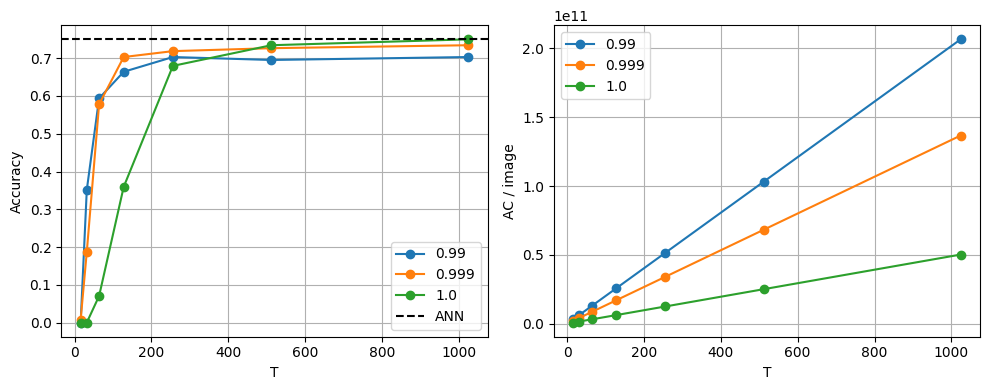

In [18]:
classification_results.to_csv(RESULTS_DIR / "classification.csv", index=False)
layer_results.to_csv(RESULTS_DIR / "layer_spikes.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for p, table in classification_results.groupby("p"):
    axes[0].plot(table["T"], table["accuracy"], "o-", label=str(p))
    axes[1].plot(table["T"], table["total_AC_per_image"], "o-", label=str(p))
axes[0].axhline(ann_accuracy, color="black", linestyle="--", label="ANN")
for ax, ylabel in zip(axes, ("Accuracy", "AC / image")):
    ax.set(xlabel="T", ylabel=ylabel)
    ax.grid()
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "classification.png")

## 13. Адаптация под другую задачу
Полученный энкодер ResNet можно использовать для другой задачи компьютерного зрения. Выберите задачу и датасет. Например, сегментация, детекция или локализация.

Замените в нужной архитектуре энкодер на спайковый ResNet и оцените качество.

В реализации используется бинарная сегментация пешеходов
[Penn-Fudan](https://www.cis.upenn.edu/~jshi/ped_html/).
Энкодер заморожен; небольшой декодер обучается только на ANN-признаках.


In [19]:
from torchvision.datasets.utils import download_and_extract_archive

seg_root = DATA_DIR / "PennFudanPed"
if not seg_root.exists():
    download_and_extract_archive(
        "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", str(DATA_DIR)
    )

seg_transform = transforms.Compose([
    transforms.Resize((SEG_SIZE, SEG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class PedestrianDataset(Dataset):
    def __init__(self, root):
        self.images = sorted((root / "PNGImages").glob("*.png"))
        self.masks = sorted((root / "PedMasks").glob("*.png"))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        with Image.open(self.images[index]) as image:
            x = seg_transform(image.convert("RGB"))
        with Image.open(self.masks[index]) as mask:
            mask = TF.resize(mask, [SEG_SIZE, SEG_SIZE], transforms.InterpolationMode.NEAREST)
            y = (TF.pil_to_tensor(mask) > 0).float()
        return x, y


seg_dataset = PedestrianDataset(seg_root)
indices = torch.randperm(len(seg_dataset), generator=torch.Generator().manual_seed(SEED)).tolist()
split = int(0.8 * len(indices))
seg_train_loader = DataLoader(
    Subset(seg_dataset, indices[:split][:SEG_TRAIN_SAMPLES]), batch_size=8, shuffle=False
)
seg_test_loader = DataLoader(
    Subset(seg_dataset, indices[split:][:SEG_TEST_SAMPLES]), batch_size=4, shuffle=False
)

In [20]:
ann_encoder = nn.Sequential(*list(ann_batch_folded.children())[:-2]).eval()


@torch.no_grad()
def collect_features(loader):
    features, masks = [], []
    for images, targets in loader:
        features.append(ann_encoder(images.to(device)).cpu())
        masks.append(targets)
    return torch.cat(features), torch.cat(masks)


train_features, train_masks = collect_features(seg_train_loader)
test_features, test_masks = collect_features(seg_test_loader)
decoder = nn.Sequential(
    nn.Conv2d(512, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 1, 1)
).to(device)
optimizer = torch.optim.Adam(decoder.parameters(), lr=1e-3)
positive_weight = (1 - train_masks.mean()) / train_masks.mean()
criterion = nn.BCEWithLogitsLoss(pos_weight=positive_weight.to(device))
feature_loader = DataLoader(TensorDataset(train_features, train_masks), batch_size=8, shuffle=True)
loss_history = []
for epoch in tqdm(range(SEG_EPOCHS), desc="Segmentation decoder"):
    decoder.train()
    epoch_loss = 0.0
    for features, masks in feature_loader:
        prediction = F.interpolate(
            decoder(features.to(device)), size=(SEG_SIZE, SEG_SIZE),
            mode="bilinear", align_corners=False,
        )
        loss = criterion(prediction, masks.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(feature_loader))
decoder.eval()
torch.save(decoder.state_dict(), RESULTS_DIR / "segmentation_decoder.pt")
pd.DataFrame({"loss": loss_history}).to_csv(RESULTS_DIR / "decoder_loss.csv", index=False)

Segmentation decoder:   0%|          | 0/50 [00:00<?, ?it/s]

In [21]:
def segmentation_scores(prediction, target):
    prediction, target = prediction.bool(), target.bool()
    dims = (1, 2, 3)
    intersection = (prediction & target).sum(dims).float()
    union = (prediction | target).sum(dims).float()
    size = prediction.sum(dims) + target.sum(dims)
    return (intersection + 1e-6) / (union + 1e-6), (2 * intersection + 1e-6) / (size + 1e-6)


@torch.inference_mode()
def decode(features):
    return F.interpolate(
        decoder(features), size=(SEG_SIZE, SEG_SIZE), mode="bilinear", align_corners=False
    ) > 0


ann_masks = decode(test_features.to(device)).cpu()
ann_iou, ann_dice = segmentation_scores(ann_masks, test_masks)
seg_rows = []
seg_example = None
for p, layer_thresholds in thresholds_by_percentile.items():
    snn = SpikingResNet18(ann_batch_folded, layer_thresholds).eval().to(device)
    scores = {t: {"iou": 0.0, "dice": 0.0, "n": 0} for t in T_CHECKPOINTS}
    for images, masks in tqdm(seg_test_loader, desc=f"Segmentation p={p}"):
        outputs = snn.forward_checkpoints(images.to(device), T_CHECKPOINTS, return_features=True)
        for t, output in outputs.items():
            prediction = decode(output["features"]).cpu()
            iou, dice = segmentation_scores(prediction, masks)
            scores[t]["iou"] += iou.sum().item()
            scores[t]["dice"] += dice.sum().item()
            scores[t]["n"] += len(images)
            if seg_example is None and p == THRESHOLD_PERCENTILE and t == max(T_CHECKPOINTS):
                seg_example = (images[0], masks[0], prediction[0])
    for t, row in scores.items():
        seg_rows.append({
            "p": p, "T": t, "ANN_IoU": ann_iou.mean().item(),
            "ANN_Dice": ann_dice.mean().item(),
            "SNN_IoU": row["iou"] / row["n"], "SNN_Dice": row["dice"] / row["n"],
        })
segmentation_results = pd.DataFrame(seg_rows)
segmentation_results.to_csv(RESULTS_DIR / "segmentation.csv", index=False)
segmentation_results

Segmentation p=0.99:   0%|          | 0/4 [00:00<?, ?it/s]

Segmentation p=0.999:   0%|          | 0/4 [00:00<?, ?it/s]

Segmentation p=1.0:   0%|          | 0/4 [00:00<?, ?it/s]

,p,T,ANN_IoU,ANN_Dice,SNN_IoU,SNN_Dice
0,0.990,16,0.31101,0.446301,0.186939,0.278516
1,0.990,32,0.31101,0.446301,0.305475,0.437610
2,0.990,64,0.31101,0.446301,0.311683,0.456634
3,0.990,128,0.31101,0.446301,0.291976,0.429848
4,0.990,256,0.31101,0.446301,0.289634,0.424624
5,0.990,512,0.31101,0.446301,0.288882,0.421978
6,0.990,1024,0.31101,0.446301,0.288661,0.420282
7,0.999,16,0.31101,0.446301,0.137604,0.203381
8,0.999,32,0.31101,0.446301,0.332201,0.479390
9,0.999,64,0.31101,0.446301,0.350574,0.503213


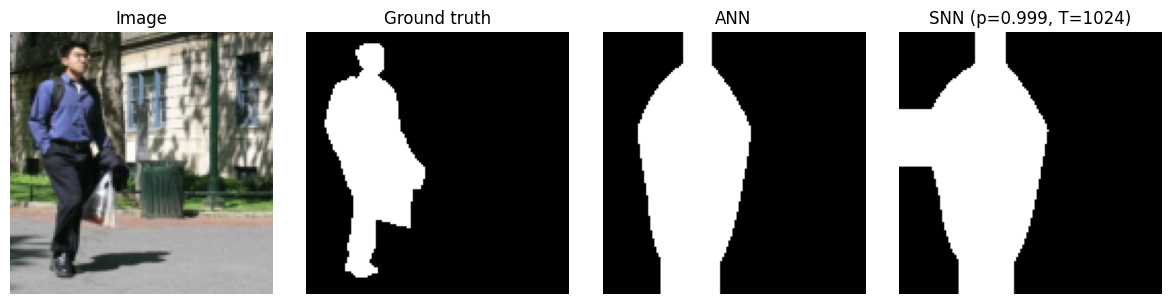

In [22]:
image, mask, prediction = seg_example
image = image * torch.tensor([0.229, 0.224, 0.225])[:, None, None]
image = image + torch.tensor([0.485, 0.456, 0.406])[:, None, None]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(image.permute(1, 2, 0).clamp(0, 1))
for ax, value in zip(axes[1:], (mask, ann_masks[0], prediction)):
    ax.imshow(value.squeeze(), cmap="gray", vmin=0, vmax=1)
for ax, title in zip(axes, ("Image", "Ground truth", "ANN", f"SNN (p={THRESHOLD_PERCENTILE:g}, T={max(T_CHECKPOINTS)})")):
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "segmentation_example.png")

## 14. Сводная таблица

При интерпретации результатов необходимо различать:

- **MAC ANN** — умножение с накоплением для плотной сети;
- **AC/SynOps SNN** — прибавление веса при входном событии;
- **residual AC** — сложения двух ветвей residual-блока;
- **spikes** — число событий, а не число синаптических операций;

Один спайк может инициировать много SynOps, поскольку связан со многими нейронами следующего слоя.

In [23]:
summary = classification_results.merge(segmentation_results, on=["p", "T"])
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
minimum_t = (
    classification_results[classification_results["accuracy_drop"] <= 0.02]
    .groupby("p")["T"].min().reindex(sorted(thresholds_by_percentile))
)
minimum_t.to_csv(RESULTS_DIR / "minimum_T.csv", header=["minimum_T"])
print("Минимальное T при потере не более 2 п.п.; NaN — подходящего T нет:")
print(minimum_t)
experiment = {
    "seed": SEED, "fast_mode": FAST_MODE, "T": T_CHECKPOINTS,
    "calibration_images": len(calibration_loader.dataset),
    "classification_images": len(classification_loader.dataset),
    "segmentation_train_images": len(seg_train_loader.dataset),
    "segmentation_test_images": len(seg_test_loader.dataset),
    "segmentation_size": SEG_SIZE, "decoder_epochs": SEG_EPOCHS,
    "folding_max_abs_error": fold_max_error,
}
(RESULTS_DIR / "experiment.json").write_text(json.dumps(experiment, indent=2))
summary


Минимальное T при потере не более 2 п.п.; NaN — подходящего T нет:
p
0.990       NaN
0.999    1024.0
1.000     512.0
Name: T, dtype: float64


,T,accuracy,accuracy_drop,spikes_per_image,spikes_per_neuron,MAC_per_image,synaptic_AC_per_image,residual_AC_per_image,total_AC_per_image,AC_to_ANN_MAC,ANN_accuracy,ANN_MAC_per_image,ANN_AC_per_image,p,ANN_IoU,ANN_Dice,SNN_IoU,SNN_Dice
0,16,0.000000,0.750000,6.051713e+06,2.621950,118525952.0,3.047522e+09,1.675336e+07,3.064275e+09,1.689168,0.75,1814073344,752640,0.990,0.31101,0.446301,0.186939,0.278516
1,32,0.351562,0.398438,1.238901e+07,5.367632,118525952.0,6.237227e+09,3.369078e+07,6.270918e+09,3.456816,0.75,1814073344,752640,0.990,0.31101,0.446301,0.305475,0.437610
2,64,0.593750,0.156250,2.509483e+07,10.872526,118525952.0,1.265410e+10,6.757585e+07,1.272167e+10,7.012766,0.75,1814073344,752640,0.990,0.31101,0.446301,0.311683,0.456634
3,128,0.664062,0.085938,5.052539e+07,21.890506,118525952.0,2.550959e+10,1.353516e+08,2.564494e+10,14.136659,0.75,1814073344,752640,0.990,0.31101,0.446301,0.291976,0.429848
4,256,0.703125,0.046875,1.013980e+08,43.931444,118525952.0,5.123009e+10,2.709065e+08,5.150100e+10,28.389701,0.75,1814073344,752640,0.990,0.31101,0.446301,0.289634,0.424624
5,512,0.695312,0.054688,2.031482e+08,88.015493,118525952.0,1.026762e+11,5.420173e+08,1.032182e+11,56.898598,0.75,1814073344,752640,0.990,0.31101,0.446301,0.288882,0.421978
6,1024,0.703125,0.046875,4.066520e+08,176.185037,118525952.0,2.055696e+11,1.084241e+09,2.066539e+11,113.917049,0.75,1814073344,752640,0.990,0.31101,0.446301,0.288661,0.420282
7,16,0.007812,0.742188,3.894993e+06,1.687535,118525952.0,2.009582e+09,1.604883e+07,2.025630e+09,1.116620,0.75,1814073344,752640,0.999,0.31101,0.446301,0.137604,0.203381
8,32,0.187500,0.562500,8.009889e+06,3.470345,118525952.0,4.102240e+09,3.226594e+07,4.134506e+09,2.279128,0.75,1814073344,752640,0.999,0.31101,0.446301,0.332201,0.479390
9,64,0.578125,0.171875,1.627739e+07,7.052301,118525952.0,8.328206e+09,6.471435e+07,8.392920e+09,4.626560,0.75,1814073344,752640,0.999,0.31101,0.446301,0.350574,0.503213


## 15. Задания для самостоятельной работы

### Обязательная часть

1. Запустите калибровку с $p\in\{0.99,0.999,1.0\}$ и объясните влияние порога на точность и число спайков.
2. Заполните таблицу для $T=16,32,64,128,256$.
3. Найдите минимальный $T$, при котором падение accuracy относительно ANN не превышает 2 процентных пунктов.
4. Сравните `spikes_per_image` и `total_AC_per_image`. В чём отличие?

### Вопросы к отчёту

- Какие ошибки конверсии уменьшаются при росте $T$?
- Почему BatchNorm необходимо свернуть до конверсии?
- Почему shortcut и основная ветвь должны иметь согласованный масштаб?
- Почему уменьшение числа спайков не гарантирует уменьшение энергии?
- Какие операции этой реализации не вошли в MAC/AC-модель?

При увеличении T уменьшаются ошибка дискретного представления активаций и влияние
начального переходного процесса. Насыщение из-за низкого порога и ошибки архитектуры
рост T не устраняет. Максимальный порог уменьшает активность, но может требовать
большего T; низкий перцентиль повышает активность и риск насыщения.

BatchNorm свёрнут с Conv в режиме eval, поэтому сохранены его фиксированные
масштаб и смещение. Обе residual-ветви складываются в исходном масштабе активаций:
IF возвращает threshold * spike.

Число спайков — число событий, а AC учитывает их распространение по связям.
Один спайк может вызвать много AC. Число операций не измеряет энергию: модель
не учитывает доступ к памяти, сравнения, обновление и сброс потенциалов,
добавление bias, MaxPool, усреднение и служебные операции. GPU выполняет плотные
свёртки, даже если тензоры содержат много нулей. ANN AC здесь учитывает сложения
residual-ветвей, SNN AC оценивается по плотности входных событий.

В сегментации обучается только небольшой декодер на ANN-признаках. Для SNN
используется тот же декодер и пороги Imagenette без адаптации. Это проверка переноса
признаков; FAST_MODE даёт предварительные оценки на небольших подвыборках.
Рекомендуемое минимальное T определяется отдельно для каждого порога таблицей
minimum_T.csv; если значения нет, условие потери 2 п.п. не достигнуто.

Точность ANN — **75%**. Лучший результат SNN — **75%** при `max`, `T=1024`.

Минимальное подходящее среди проверенных значений — **T=512** при `max`:
точность **73.4375%**, потеря **1.5625 п.п.**

| Правило порога | Минимальное T с потерей до 2 п.п. |
|---|---:|
| p99 | Не найдено |
| p99.9 | 1024 |
| max | 512 |

Для лучшего по точности режима (`max`, `T=1024`) IoU ANN/SNN — **0.311 / 0.318**,
Dice — **0.446 / 0.458**.

В текущем запуске использованы 128 калибровочных и 128 отдельных тестовых
изображений Imagenette, 64 обучающих и 16 тестовых изображений Penn-Fudan.
Результаты FAST_MODE являются предварительными оценками на малых выборках.


## 16. Формат отчёта

Отчёт должен содержать:

1. краткое описание алгоритма конверсии;
2. проверку эквивалентности ANN до и после BatchNorm folding;
3. таблицу accuracy, MAC, AC и числа спайков для всех $T$;
4. график accuracy–$T$ и AC–$T$;
5. таблицу IoU/Dice для задачи сегментации;
6. примеры исходного изображения, разметки, ANN- и SNN-предсказания;
7. обсуждение ограничений принятой модели стоимости;
8. вывод о рекомендуемом $T$.